# Real-time data assimilation with the convolutional autoencoder echo state network

The convolutional autoencoder echo state network (CAE-ESN) is a reduced-order model of a flow: a convolutional autoencoder (CAE) compresses each snapshot into a few reduced coordinates, and an echo state network (ESN) forecasts the reduced coordinates in time [1]. In this notebook, we assimilate sparse and noisy measurements of the vorticity into the CAE-ESN with an ensemble Kalman filter (EnKF), following [2]. Tutorial 45 applies the same method to the Kuramoto–Sivashinsky equation, with a record that anyone can generate; this notebook needs a record that is not distributed with romda (section 1). The schematic shows the method: the encoder initializes the ensemble, the ESN forecasts each member, the EnKF updates the reservoir states with the measurements, and the decoder maps the forecast back to the vorticity field.

<a><img src="../../docs/figs/DA/CAE-ESN_DA.png" width=900px></a>

The autoencoder comes from the repository of [2], [github.com/MagriLab/DA-CAE-ESN](https://github.com/MagriLab/DA-CAE-ESN); romda reimplements the network as `MultiScaleCAE`, with the same layer names, so the weights of [2] load unchanged (`MultiScaleCAE.load_state_dicts`).

[1] A. Racca, N. A. K. Doan & L. Magri (2023). Predicting turbulent dynamics with the convolutional autoencoder echo state network. *J. Fluid Mech.* 975, A2.

[2] E. Özalp, A. Nóvoa & L. Magri (2026). Real-time forecasting of chaotic dynamics from sparse data and autoencoders. *Comput. Methods Appl. Mech. Eng.* 450, 118600.

In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import torch

from romda.plotting import Palette

device = 'cuda' if torch.cuda.is_available() else 'cpu'

## 1. The Kolmogorov flow

The Kolmogorov flow is a two-dimensional incompressible flow in a periodic square, driven by a sinusoidal body force. We use the vorticity at Reynolds number 30 on a $48 \times 48$ grid, computed with jax-cfd, which is the dataset on which [1, 2] train the CAE-ESN. Each snapshot is $\Delta t = 0.1$ apart, and the leading Lyapunov exponent is $\lambda_1 \approx 0.05$, so one Lyapunov time, $1/\lambda_1$, spans 200 snapshots. As in [2], we discard the first 1000 snapshots (the transient), train on the next 50000, and keep 20000 for validation; the snapshots after them are the test set. The record was computed with jax-cfd and is not distributed with romda. The notebook reads it from the folder in the environment variable `DATA_ROOT` (default `data`), under `Kolmogorov/jax-cfd/`: to run the notebook, compute a record of the same flow with jax-cfd and set `DATA_ROOT` before starting Jupyter. The figure shows four snapshots of the test set, (a) to (d), one every five time units.

training, validation and test snapshots: (50000, 48, 48) (20000, 48, 48) (5000, 48, 48)


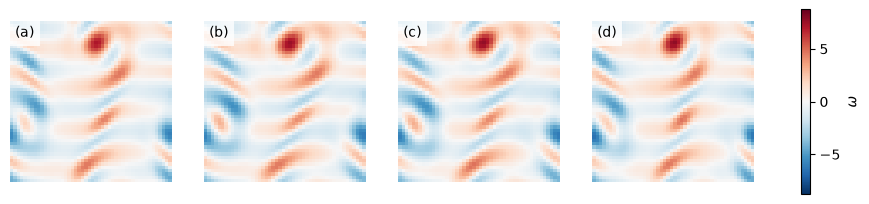

In [2]:
import os

H5 = os.path.join(os.environ.get('DATA_ROOT', 'data'), 'Kolmogorov', 'jax-cfd', 'Kolmogorov_Re30_drag0.0_jaxcfd_res48.h5')
N_trans, N_train, N_val, N_test = 1000, 50000, 20000, 5000
with h5py.File(H5, 'r') as f:
    W_train = f['vorticity'][N_trans:N_trans + N_train]
    W_val = f['vorticity'][N_trans + N_train:N_trans + N_train + N_val]
    W_test = f['vorticity'][N_trans + N_train + N_val:N_trans + N_train + N_val + N_test]

dt, t_lyap = 0.1, 1 / 0.05
w_max = np.abs(W_train).max()                                  # colour scale of the figures
print('training, validation and test snapshots:', W_train.shape, W_val.shape, W_test.shape)

fig, axs = plt.subplots(1, 4, figsize=(12, 3))
for ax, k, label in zip(axs, (0, 50, 100, 150), '(a) (b) (c) (d)'.split()):
    im = ax.imshow(W_test[k].T, origin='lower', cmap='RdBu_r', vmin=-w_max, vmax=w_max)
    ax.text(1, 46, label, va='top', bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
    ax.axis('off')
fig.colorbar(im, ax=axs, shrink=0.8, label=r'$\omega$')

## 2. The autoencoder

`MultiScaleCAE` has three branches of convolutions with kernels of size 3, 5 and 7, whose reduced coordinates and reconstructions are summed; every layer ends with a hyperbolic tangent, so the vorticity is divided by its maximum absolute value. The network is that of [1, 2], with 16 reduced coordinates, trained in romda on the training and validation snapshots of this record with the settings of [2]. With the weights of [2], `MultiScaleCAE` and the original network give the same reduced coordinates and reconstructions, which verifies the reimplementation. We compare the reconstruction of a test snapshot, (a), by the CAE, (b), with the proper orthogonal decomposition (POD) truncated to the same number of modes, (c); panels (d) and (e) are their absolute errors.

16 reduced coordinates, branch kernels (3, 5, 7), 149623 parameters


1 - Energy on the test set: CAE 1.3e-03, POD 4.6e-02


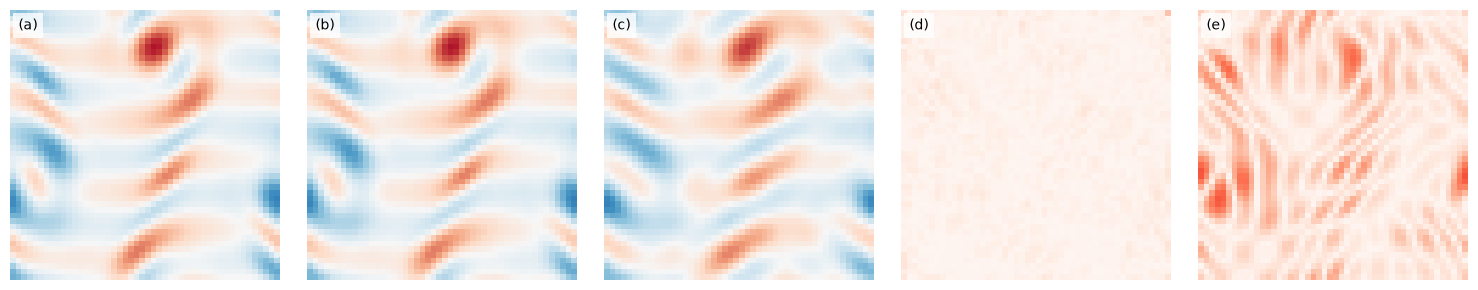

In [3]:
from romda.models.data_driven import MultiScaleCAE

import json

options = json.load(open('../weights/MultiScaleCAE_kolmogorov_re30_r16.json'))
cae = MultiScaleCAE.from_trained(options, dict(np.load('../weights/MultiScaleCAE_kolmogorov_re30_r16.npz')), device=device)
print(f'{cae.N_latent} reduced coordinates, branch kernels {cae.kernel_sizes}, {cae.n_params} parameters')

def energy_error(W, W_hat):
    """1 - Energy: the squared reconstruction error relative to the energy of the field."""
    return np.sum((W - W_hat) ** 2) / np.sum(W ** 2)

X_test = W_test[None]                                   # (Nu, N_t, Nx, Ny)
W_cae = cae.reconstruct(X_test).T.reshape(W_test.shape)

V = np.linalg.svd(W_train[::5].reshape(-1, 48 * 48), full_matrices=False)[2][:cae.N_latent]
W_pod = (W_test.reshape(N_test, -1) @ V.T @ V).reshape(W_test.shape)
print(f'1 - Energy on the test set: CAE {energy_error(W_test, W_cae):.1e}, POD {energy_error(W_test, W_pod):.1e}')

k = 0
fields = [W_test[k], W_cae[k], W_pod[k], np.abs(W_cae[k] - W_test[k]), np.abs(W_pod[k] - W_test[k])]
fig, axs = plt.subplots(1, 5, figsize=(15, 3))
for i, (ax, field) in enumerate(zip(axs, fields)):
    if i < 3:
        ax.imshow(field.T, origin='lower', cmap='RdBu_r', vmin=-w_max, vmax=w_max)
    else:
        ax.imshow(field.T, origin='lower', cmap='Reds', vmin=0, vmax=0.3 * w_max)
    ax.text(1, 46, f'({"abcde"[i]})', va='top', bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
    ax.axis('off')
fig.tight_layout()

The CAE reconstructs the vorticity more accurately than POD with the same number of coordinates, because the decoder is nonlinear.

## 3. The CAE-ESN

`MultiScaleCAE_ESN` combines the autoencoder with `ESN_model` through `LatentROM`. We pass the trained autoencoder with `projector=`, so the training data only train the ESN, on the reduced coordinates of the training snapshots. The ESN has the hyperparameters that [2] selected: 5000 units, spectral radius 0.1, input scaling 0.8, Tikhonov factor $10^{-10}$, a dense input matrix, and inputs normalized by their standard deviation. The sensors, at which the model reads the decoded vorticity, form a regular grid of 36 points.

In [4]:
from romda.models.data_driven import MultiScaleCAE_ESN

n_sensors = 36
xx, yy = np.meshgrid(np.linspace(0, 47, 6, dtype=int), np.linspace(0, 47, 6, dtype=int), indexing='ij')
sensors = np.sort((xx * 48 + yy).ravel())                 # grid indices x * Ny + y

rom = MultiScaleCAE_ESN(data=W_train[None], dt=dt, projector=cae, sensor_locations=sensors,
                        N_units=5000, N_wash=100, t_train=(N_train - 1000) * dt, t_val=1000 * dt, t_test=0.,
                        upsample=1, rho=0.1, sigma_in=0.8, tikh=1e-10, hyperparameters_to_optimize=[],
                        Win_type='dense', norm_method='std', bias_in=np.array([1.]), connect=10, noise=1e-3,
                        plot_training=False, seed=0)
print(f'state of the model: {rom.N_latent} reduced coordinates + {rom.N_units} reservoir states; {rom.Nq} observables')

state of the model: 16 reduced coordinates + 5000 reservoir states; 36 observables


Without data assimilation, the CAE-ESN is initialized on 100 encoded snapshots (the washout) and then forecasts in closed loop: each output is the next input. We measure the error of the decoded vorticity, normalized by the root-mean-square of the true vorticity, from several initial times in the test set.

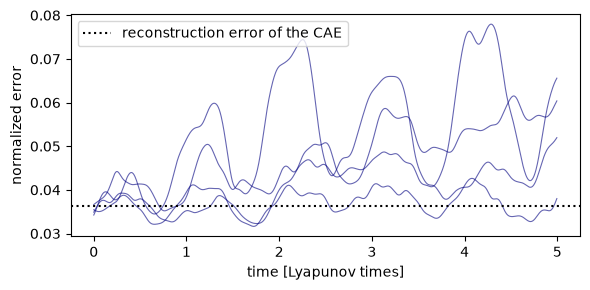

In [5]:
Z_test = cae.encode(X_test).T                            # (N_t, N_latent)
rms = np.sqrt(np.mean(np.sum(W_test.reshape(N_test, -1) ** 2, axis=1)))
n_forecast = 1000
t_f = np.arange(n_forecast) * dt / t_lyap

fig, ax = plt.subplots(figsize=(6, 3))
for i0 in range(0, N_test - n_forecast - 100, 1000):
    Z_f, _ = rom.closed_loop(Z_test[i0:i0 + 100 + n_forecast], n_forecast)
    W_f = rom.decode(Z_f.T).T
    err = np.linalg.norm(W_f - W_test[i0 + 100:i0 + 100 + n_forecast].reshape(n_forecast, -1), axis=1) / rms
    ax.plot(t_f, err, color=Palette.UNBIASED, lw=0.8, alpha=0.6)
ax.set(xlabel='time [Lyapunov times]', ylabel='normalized error')
ax.axhline(np.sqrt(energy_error(W_test, W_cae)), color='k', ls=':', label='reconstruction error of the CAE')
ax.legend()
fig.tight_layout()

## 4. Data assimilation

We now forecast without knowing the initial state. The ensemble of 50 CAE-ESNs starts from reservoir states visited during training, so the members are unrelated to the true flow. Every $\Delta t_\mathrm{obs} = 10\,\Delta t$, the 36 sensors measure the vorticity with a noise of standard deviation 10 % of the local standard deviation, and the EnKF updates the augmented state of each member, i.e. its reduced coordinates and its reservoir. We assimilate during five Lyapunov times and then forecast for five more.

The observation operator is nonlinear, because the decoder maps the reduced coordinates to the vorticity at the sensors; the EnKF does not need its Jacobian, because it estimates the covariance between the state and the observables from the ensemble.

In [6]:
from romda.observations import Observations
from romda.estimators import EnKF
from romda.data_assimilation import run_da_loop

W_flat = W_test.reshape(N_test, -1)
sigma = 0.1 * W_flat.std(axis=0)[sensors]
rng = np.random.default_rng(1)
n_obs = 10
truth = Observations(y_raw=W_flat[:, sensors] + sigma * rng.standard_normal((N_test, n_sensors)),
                     y_true=W_flat[:, sensors], t_true=np.arange(N_test) * dt,
                     t_start=n_obs * dt, t_stop=5 * t_lyap, Nt_obs=n_obs)

ensemble = EnKF(parent_model=rom, m=50)
filt = run_da_loop(ensemble, truth, Cdd=np.diag(sigma ** 2), t_extra=5 * t_lyap)

error: initial ensemble 0.91; after 1 Lyapunov time 0.041; 5 Lyapunov times after the last measurement 0.069


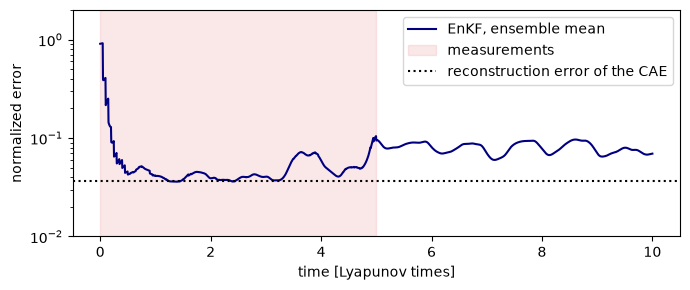

In [7]:
model = filt.model
t = np.asarray(model.hist_t)
keep = np.r_[t[1:] != t[:-1], True]                      # at the observation times, keep the analysis
t, Z = t[keep], model.hist[keep, :rom.N_latent]          # (N_t, N_latent, m)
idx = np.rint(t / dt).astype(int)
W_mean = rom.decode(Z.mean(-1).T).T                      # decoded ensemble mean
err_da = np.linalg.norm(W_mean - W_flat[idx], axis=1) / rms
spread = np.sqrt(np.mean(np.var(np.stack([rom.decode(Z[::10, :, j].T).T for j in range(filt.m)]), axis=0).sum(-1))) / rms

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t / t_lyap, err_da, color=Palette.UNBIASED, label='EnKF, ensemble mean')
ax.axvspan(0, truth.t_obs[-1] / t_lyap, color=Palette.OBS, alpha=0.1, label='measurements')
ax.axhline(np.sqrt(energy_error(W_test, W_cae)), color='k', ls=':', label='reconstruction error of the CAE')
ax.set(yscale='log', xlabel='time [Lyapunov times]', ylabel='normalized error', ylim=[1e-2, 2])
ax.legend(loc='upper right')
fig.tight_layout()
print(f'error: initial ensemble {err_da[0]:.2f}; after 1 Lyapunov time {err_da[np.searchsorted(t, t_lyap)]:.3f}; '
      f'5 Lyapunov times after the last measurement {err_da[-1]:.3f}')

Within the first Lyapunov time, the EnKF drives the ensemble from a state unrelated to the flow to the true state, and the error falls to the reconstruction error of the autoencoder, which is the lower bound of any CAE-ESN forecast. After the last measurement, the ensemble keeps forecasting the flow, with an error that stays close to that of the CAE-ESN from a known initial state (the figure of section 3). The snapshots below compare, by column, (a) the true vorticity, (b) the measurements, (c) the decoded ensemble mean and (d) its absolute error, by row at three times: before the first analysis, during the assimilation, and after the last measurement. The histogram compares the distribution of the true and forecast vorticity after the last measurement.

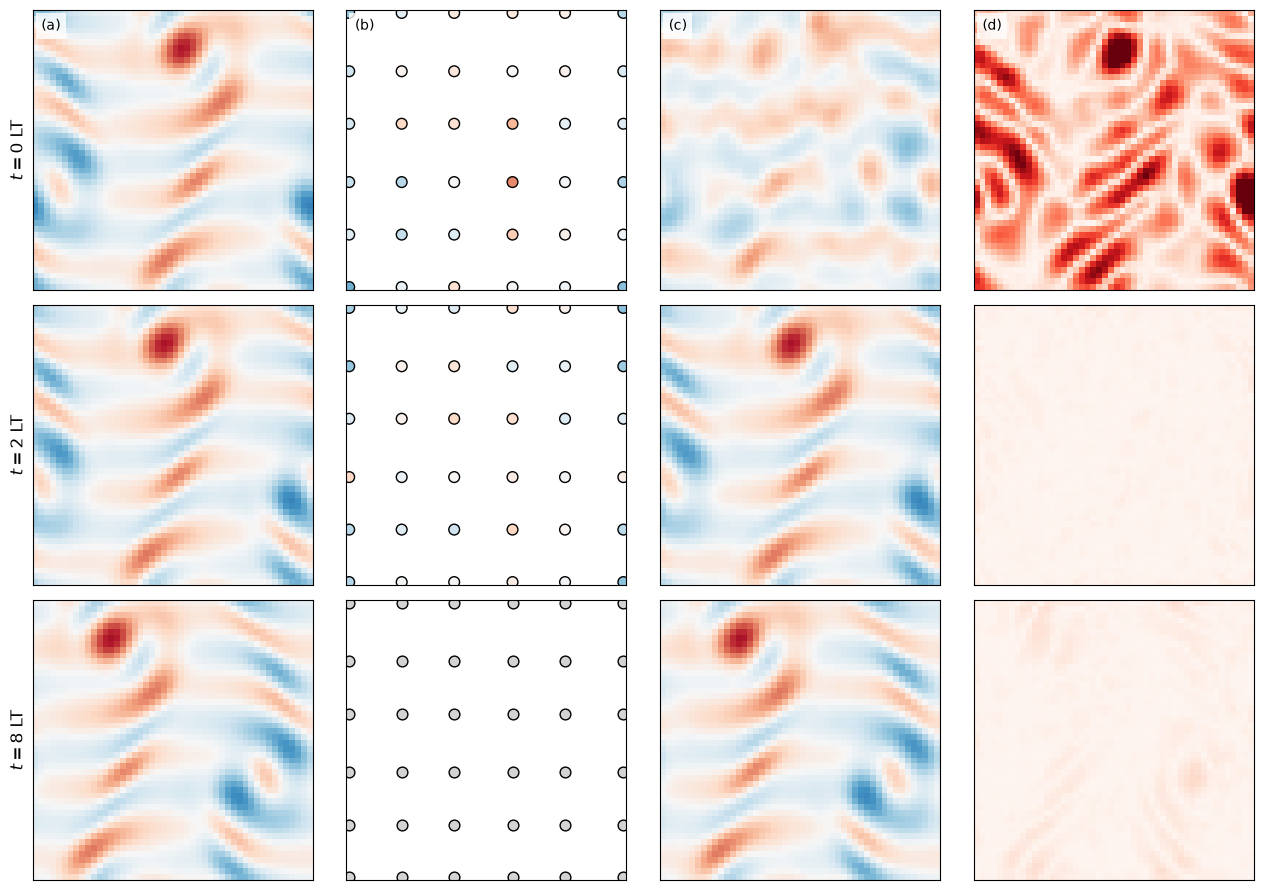

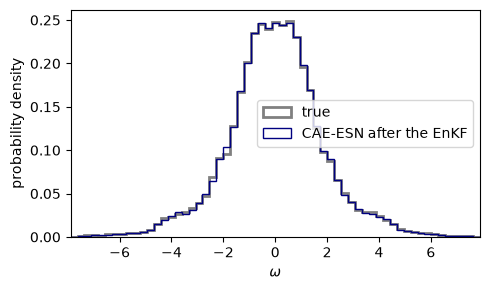

In [8]:
times = [0, 2 * t_lyap, 8 * t_lyap]
fig, axs = plt.subplots(3, 4, figsize=(13, 9))
sx, sy = np.unravel_index(sensors, (48, 48))
for row, tt in zip(axs, times):
    i = np.argmin(np.abs(t - tt))
    true, est = W_flat[idx[i]].reshape(48, 48), W_mean[i].reshape(48, 48)
    row[0].imshow(true.T, origin='lower', cmap='RdBu_r', vmin=-w_max, vmax=w_max)
    row[1].imshow(np.full((48, 48), np.nan).T, origin='lower')
    if t[i] <= truth.t_obs[-1]:
        row[1].scatter(sx, sy, c=truth.y_raw[idx[i]], cmap='RdBu_r', vmin=-w_max, vmax=w_max, s=60, edgecolor='k')
    else:                                                # no measurements after the assimilation window
        row[1].scatter(sx, sy, color='lightgrey', s=60, edgecolor='k')
    row[2].imshow(est.T, origin='lower', cmap='RdBu_r', vmin=-w_max, vmax=w_max)
    row[3].imshow(np.abs(est - true).T, origin='lower', cmap='Reds', vmin=0, vmax=0.5 * w_max)
    row[0].set_ylabel(f'$t = {t[i] / t_lyap:.0f}$ LT', fontsize=12)
for ax, label in zip(axs[0], '(a) (b) (c) (d)'.split()):
    ax.text(1, 46, label, va='top', bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
for ax in axs.flat:
    ax.set(xticks=[], yticks=[], xlim=[-0.5, 47.5], ylim=[-0.5, 47.5])
fig.tight_layout()

after = t > truth.t_obs[-1]
fig, ax = plt.subplots(figsize=(5, 3))
bins = np.linspace(W_flat.min(), W_flat.max(), 60)
ax.hist(W_flat[idx[after]].ravel(), bins=bins, density=True, histtype='step', color=Palette.TRUE, lw=2, label='true')
ax.hist(W_mean[after].ravel(), bins=bins, density=True, histtype='step', color=Palette.UNBIASED, label='CAE-ESN after the EnKF')
ax.set(xlabel=r'$\omega$', ylabel='probability density', xlim=bins[[0, -1]])
ax.legend()
fig.tight_layout()

In summary, the EnKF brings the CAE-ESN from an ensemble unrelated to the flow to the true state from sparse and noisy measurements, and the CAE-ESN keeps forecasting the flow after the measurements stop.